# Лабораторная работа №11: Alignment VLM по предпочтениям

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Собрать preference pairs без length/style shortcut.
- Провести LoRA preference optimization на 2B fallback.
- Сравнить base/SFT/aligned по win rate и hallucinations.


## Теоретическая часть

Preference optimization использует пары chosen/rejected. DPO увеличивает относительную вероятность chosen относительно reference policy без отдельной reward model. Для VLM важно, чтобы изображения и prompts совпадали в обеих ветвях.


### Математическая постановка

$$\mathcal L_{DPO}=-\log\sigma\left(\beta[\log\tfrac{\pi_\theta(y_w|x)}{\pi_{ref}(y_w|x)}-\log\tfrac{\pi_\theta(y_l|x)}{\pi_{ref}(y_l|x)}]\right).$$


### Материалы

- [DPO paper](https://arxiv.org/abs/2305.18290)
- [TRL цикл оптимизации DPO](https://huggingface.co/docs/trl/dpo_trainer)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практический протокол

Preference dataset является экспертным входом; пример с несуществующим cats.jpg не используется. Нужен адаптер lab 9 и GPU. При смене версии TRL сверьте мультимодальный цикл оптимизации DPO и зафиксируйте версии. `FAST_DEV_RUN=True` выполняет реальные два шага DPO, но не является evidence качества. Без заполненного слепого экспертного аудита итоговая метрика не создаётся.

In [1]:
from pathlib import Path
import json, os, random, time
import numpy as np
SEED = 42
FAST_DEV_RUN = False  # True: проверка механики на малой выборке, НЕ отчётный эксперимент
ARTIFACTS = Path('artifacts'); ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
def save_json(name, data):
    (ARTIFACTS/name).write_text(json.dumps(data, ensure_ascii=False, indent=2, default=str))
from pathlib import Path
import json, hashlib
from datasets import load_dataset

SCIENCEQA_ID = 'derek-thomas/ScienceQA'
SCIENCEQA_REVISION = 'f18b0a70359ebfb41f658fd564208d0355b013f4'

def prepare_scienceqa(directory, smoke=False):
    """Fixed official splits, image-level deduplication, explicitly defined shifts."""
    directory = Path(directory).resolve(); directory.mkdir(parents=True, exist_ok=True)
    manifest = directory / ('manifest-smoke.jsonl' if smoke else 'manifest.jsonl')
    limits = {'train': 8 if smoke else 512, 'validation': 4 if smoke else 64,
              'id_test': 4 if smoke else 64, 'ood_test': 4 if smoke else 64,
              'general_test': 4 if smoke else 64}
    if manifest.exists():
        records = [json.loads(s) for s in manifest.read_text().splitlines()]
        if all(Path(r['image']).is_file() for r in records) and all(sum(r['split']==s for r in records)==n for s,n in limits.items()):
            return manifest
    records, seen, counts = [], set(), dict.fromkeys(limits, 0)
    for official in ('train', 'validation', 'test'):
        data = load_dataset(SCIENCEQA_ID, revision=SCIENCEQA_REVISION, split=official, streaming=True)
        for index, row in enumerate(data):
            image = row['image']
            if image is None: continue
            if official != 'test':
                if row['subject'] != 'natural science' or int(row['grade'].removeprefix('grade')) > 6: continue
                split = official
            elif row['subject'] != 'natural science': split = 'general_test'
            elif int(row['grade'].removeprefix('grade')) > 6: split = 'ood_test'
            else: split = 'id_test'
            if counts[split] >= limits[split]: continue
            image = image.convert('RGB')
            digest = hashlib.sha256(str(image.size).encode()+image.tobytes()).hexdigest()
            if digest in seen: continue
            seen.add(digest)
            path = directory / f'{digest}.png'; image.save(path)
            answer = int(row['answer']); choices = row['choices']
            question = row['question']+'\n'+'\n'.join(f'{chr(65+i)}. {v}' for i,v in enumerate(choices))+'\nReturn only the letter of the correct option.'
            records.append({'id': f'scienceqa-{official}-{index}', 'split': split,
                            'image': str(path), 'question': question, 'answer': chr(65+answer),
                            'choices': choices, 'answer_index': answer, 'label_type': 'multiple_choice',
                            'license': 'MIT (code license, lupantech/ScienceQA)',
                            'source_url': f'https://huggingface.co/datasets/{SCIENCEQA_ID}/tree/{SCIENCEQA_REVISION}',
                            'subject':row['subject'], 'grade':row['grade'], 'image_sha256':digest})
            counts[split] += 1
            required = [official] if official != 'test' else ['id_test','ood_test','general_test']
            if all(counts[s] == limits[s] for s in required): break
    if counts != limits: raise RuntimeError(f'Insufficient licensed image examples: {counts}; expected {limits}')
    manifest.write_text('\n'.join(json.dumps(r,ensure_ascii=False) for r in records)+'\n')
    (directory/'ATTRIBUTION.md').write_text('ScienceQA — Lu et al., NeurIPS 2022. Dataset distribution: '+SCIENCEQA_ID+'\nRevision: '+SCIENCEQA_REVISION+'\nDataset-card license: CC-BY-SA-4.0, https://creativecommons.org/licenses/by-sa/4.0/\nOriginal project: https://scienceqa.github.io/\nImage subsets and manifests retain attribution; downloaded images are not committed to this course.\nID: natural science grades 1–6; OOD: natural science grades 7–12; general: other subjects. This is an operational shift, not a claim of universal model ability.\n')
    return manifest


## Оценивание

Десять обязательных предметных этапов — по 1 баллу каждый, всего 10 баллов. Отдельное творческое исследование — до 1 дополнительного балла. Каждый этап принимается по указанному наблюдаемому результату.

### Предпочтения из визуальных ответов

*Вес: 1 балл.*

**Постановка.** Подготовьте ScienceQA через открытый загрузчик. Для каждого изображения chosen — правильная буква, rejected — следующий неверный вариант. Явно пометьте: это предпочтения на основе эталонной разметки, а не экспертные оценки полезности.

**Результат.** Список пар с provenance.

**Критерий принятия.** Изображения существуют, ответы различаются и соответствуют вариантам; лицензия и источник сохранены.


In [2]:
import hashlib, re, shutil, math
from collections import Counter, defaultdict
from PIL import Image

def load_jsonl(path):
    path = Path(path)
    return [json.loads(s) for s in path.read_text().splitlines() if s.strip()] if path.exists() else []

LIMITS = {'train': 8 if FAST_DEV_RUN else 512, 'validation': 4 if FAST_DEV_RUN else 64, 'id_test': 4 if FAST_DEV_RUN else 64,
          'ood_test': 4 if FAST_DEV_RUN else 64, 'general_test': 4 if FAST_DEV_RUN else 64}
manifest_path = Path(prepare_scienceqa(os.getenv('CV_DATA_DIR', 'data/lab9'), smoke=FAST_DEV_RUN))     # открытый загрузчик ScienceQA, фиксированная ревизия
records = load_jsonl(manifest_path)
by_split = defaultdict(list)
for r in records: by_split[r['split']].append(r)
assert {s: len(v) for s, v in by_split.items()} == LIMITS

def make_pair(r):
    """chosen = правильная буква, rejected = следующий (циклически) неверный вариант. Это предпочтение ИЗ ЭТАЛОННОЙ РАЗМЕТКИ, не экспертная оценка полезности."""
    n = len(r['choices']); ci = r['answer_index']; ri = (ci + 1) % n
    return {'id': r['id'], 'split': r['split'], 'image': r['image'], 'prompt': r['question'],
            'chosen': chr(65 + ci), 'rejected': chr(65 + ri), 'chosen_text': r['choices'][ci], 'rejected_text': r['choices'][ri],
            'provenance': {'type': 'label-derived', 'rule': 'chosen = эталонная буква; rejected = следующий вариант по кругу',
                           'human_preference': False, 'source_dataset': SCIENCEQA_ID, 'revision': SCIENCEQA_REVISION,
                           'source_url': r['source_url'], 'dataset_license': 'CC-BY-SA-4.0 (карточка датасета); code MIT'},
            'subject': r['subject'], 'grade': r['grade'], 'image_sha256': r['image_sha256']}

pairs_all = [make_pair(r) for r in by_split['train']]                         # official train -> пары для DPO
for p in pairs_all:
    assert Path(p['image']).is_file() and p['prompt'].strip()
    assert p['chosen'] != p['rejected'] and p['chosen_text'] != p['rejected_text']
    assert f"{p['chosen']}. {p['chosen_text']}" in p['prompt'] and f"{p['rejected']}. {p['rejected_text']}" in p['prompt']   # ответы соответствуют вариантам
    assert p['provenance']['source_url'] and p['provenance']['dataset_license']
print('пар:', len(pairs_all), '| пример:', {k: pairs_all[0][k] for k in ('chosen', 'rejected', 'chosen_text', 'rejected_text')})

README.md:   0%|          | 0.00/10.3k [00:00<?, ?B/s]

пар: 512 | пример: {'chosen': 'A', 'rejected': 'B', 'chosen_text': 'black rockfish', 'rejected_text': 'sea otter'}


### Отложенный тест и смещения пар

*Вес: 1 балл.*

**Постановка.** Используйте official train для DPO и ID test для итоговой оценки. Сверьте ID и хеши изображений. Посчитайте распределение типов ошибок и долю случаев, где chosen длиннее rejected.

**Результат.** preferences.jsonl и pair_audit.json.

**Критерий принятия.** Нет пересечений; длина ответа не используется как скрытый эталон правильности.


In [3]:
STEPS = 2 if FAST_DEV_RUN else 40                    # optimizer steps
ACCUM = 2 if FAST_DEV_RUN else 8                     # пар на один optimizer step
N_PAIRS = STEPS * ACCUM
sel = np.random.RandomState(SEED).permutation(len(pairs_all))[:N_PAIRS]
used = set(int(i) for i in sel)
pairs = [pairs_all[i] for i in sel]                  # пары в фиксированном порядке обучения
with (ARTIFACTS / 'preferences.jsonl').open('w') as f:
    for i, p in enumerate(pairs_all): f.write(json.dumps({**p, 'used_in_dpo': i in used}, ensure_ascii=False) + '\n')

test_splits = ('id_test', 'ood_test', 'general_test')
tr_ids = {p['id'] for p in pairs_all}; tr_hash = {p['image_sha256'] for p in pairs_all}
te_ids = {r['id'] for s in test_splits for r in by_split[s]}; te_hash = {r['image_sha256'] for s in test_splits for r in by_split[s]}
assert not tr_ids & te_ids and not tr_hash & te_hash, 'пересечение train и test'
assert {r['id'] for r in by_split['validation']}.isdisjoint(tr_ids | te_ids)

def letter_stats(ps):
    c = Counter(p['chosen'] for p in ps); rj = Counter(p['rejected'] for p in ps); n = len(ps)
    return {'chosen_letters': dict(sorted(c.items())), 'rejected_letters': dict(sorted(rj.items())), 'majority_chosen_letter_share': max(c.values()) / n}
len_ch = [len(p['chosen']) for p in pairs]; len_rj = [len(p['rejected']) for p in pairs]
len_txt = [(len(p['chosen_text']), len(p['rejected_text'])) for p in pairs]
audit = {'n_pairs_total': len(pairs_all), 'n_pairs_used_in_dpo': len(pairs), 'train_test_overlap': {'ids': 0, 'image_sha256': 0},
         'test_for_final_evaluation': 'id_test', 'n_id_test': len(by_split['id_test']),
         'error_type_distribution': {'rejected_is_next_option_cyclic': len(pairs)},          # все rejected устроены одинаково - это шаблон, а не разнообразие ошибок
         'letter_length': {'chosen_longer_share': float(np.mean([a > b for a, b in zip(len_ch, len_rj)])), 'equal_share': float(np.mean([a == b for a, b in zip(len_ch, len_rj)]))},
         'option_text_length': {'chosen_text_longer_share': float(np.mean([a > b for a, b in len_txt])), 'equal_share': float(np.mean([a == b for a, b in len_txt]))},
         'length_used_as_label': False, 'letters_used_pairs': letter_stats(pairs), 'letters_all_pairs': letter_stats(pairs_all),
         'known_shortcut': 'rejected всегда следующая по кругу буква после chosen: пары несут позиционный шаблон; метки - из эталона, не из предпочтений людей'}
save_json('pair_audit.json', audit)
print(json.dumps({k: audit[k] for k in ('n_pairs_total', 'n_pairs_used_in_dpo', 'letter_length', 'option_text_length')}, ensure_ascii=False))
print('буквы chosen:', audit['letters_used_pairs']['chosen_letters'], '| доля самой частой:', round(audit['letters_used_pairs']['majority_chosen_letter_share'], 3))

{"n_pairs_total": 512, "n_pairs_used_in_dpo": 320, "letter_length": {"chosen_longer_share": 0.0, "equal_share": 1.0}, "option_text_length": {"chosen_text_longer_share": 0.38125, "equal_share": 0.16875}}
буквы chosen: {'A': 132, 'B': 143, 'C': 44, 'D': 1} | доля самой частой: 0.447


### Начальная и фиксированная политики

*Вес: 1 балл.*

**Постановка.** Создайте обучаемый адаптер и отдельный фиксированный reference. Используйте адаптер работы 09, если он доступен; иначе обе политики начинаются с опубликованной instruction-tuned модели. Запишите выбранный источник.

**Результат.** reference_policy.json.

**Критерий принятия.** Начальные политики совпадают; параметры reference не обновляются; запуск без адаптера 09 не называется продолжением собственного SFT.


In [4]:
!pip install -U bitsandbytes>=0.46.1

In [5]:
!mkdir -p artifacts/lab9_adapter
!unzip -o artifacts/lab9_adapter.zip -d artifacts/lab9_adapter

Archive:  artifacts/lab9_adapter.zip
   creating: artifacts/lab9_adapter/checkpoint-100/
   creating: artifacts/lab9_adapter/checkpoint-20/
   creating: artifacts/lab9_adapter/checkpoint-40/
   creating: artifacts/lab9_adapter/checkpoint-60/
   creating: artifacts/lab9_adapter/checkpoint-80/
  inflating: artifacts/lab9_adapter/config_fingerprint.json  
  inflating: artifacts/lab9_adapter/preprocessor_config.json  
  inflating: artifacts/lab9_adapter/added_tokens.json  
  inflating: artifacts/lab9_adapter/train_results.json  
  inflating: artifacts/lab9_adapter/tokenizer.json  
  inflating: artifacts/lab9_adapter/eval_results.json  
  inflating: artifacts/lab9_adapter/vocab.json  
  inflating: artifacts/lab9_adapter/trainer_state.json  
  inflating: artifacts/lab9_adapter/special_tokens_map.json  
  inflating: artifacts/lab9_adapter/merges.txt  
  inflating: artifacts/lab9_adapter/training_eval_loss.png  
  inflating: artifacts/lab9_adapter/README.md  
  inflating: artifacts/lab9_adapte

In [6]:
import torch
from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration, BitsAndBytesConfig
from peft import PeftModel, LoraConfig, get_peft_model
assert torch.cuda.is_available(), 'Нужен GPU: без него DPO не выполняется (демонстрационные значения не создаются)'
MODEL_ID = os.getenv('CV_DPO_MODEL', 'Qwen/Qwen2.5-VL-3B-Instruct')              # 2B-fallback: CV_DPO_MODEL=Qwen/Qwen2-VL-2B-Instruct (адаптер 09 тогда не подходит)
IMAGE_MAX_PIXELS, MAX_NEW_TOKENS, DEVICE = 262144, 8, 'cuda'

def find_lab9_adapter():
    for c in [os.getenv('CV_LAB9_ADAPTER', '__none__'), 'artifacts/lab9_adapter', '../lab09/artifacts/lab9_adapter', '../lab9/artifacts/lab9_adapter']:
        if (Path(c) / 'adapter_model.safetensors').is_file(): return Path(c)
    return None
adapter09 = find_lab9_adapter() if MODEL_ID == 'Qwen/Qwen2.5-VL-3B-Instruct' else None
REF_MODE = 'adapter09' if adapter09 else 'base'

processor = AutoProcessor.from_pretrained(MODEL_ID, max_pixels=IMAGE_MAX_PIXELS)
quant = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type='nf4', bnb_4bit_compute_dtype=torch.float16, bnb_4bit_use_double_quant=True)
base = Qwen2_5_VLForConditionalGeneration.from_pretrained(MODEL_ID, quantization_config=quant, device_map='auto', torch_dtype=torch.float16)
if REF_MODE == 'adapter09':
    model = PeftModel.from_pretrained(base, str(adapter09), adapter_name='default', is_trainable=True)        # обучаемая политика = SFT-адаптер 09
    model.load_adapter(str(adapter09), adapter_name='reference', is_trainable=False)                           # отдельная замороженная копия
else:
    lcfg = LoraConfig(r=8, lora_alpha=16, lora_dropout=0.0, bias='none', task_type='CAUSAL_LM',
                      target_modules=r'^(?!.*visual).*\.(q_proj|k_proj|v_proj|o_proj|gate_proj|up_proj|down_proj)$')   # только языковая часть
    model = get_peft_model(base, lcfg, adapter_name='default')    # B=0: начальная политика совпадает с исходной моделью; reference = model.disable_adapter()

def set_trainable_flags(m):
    """Обучается только LoRA-адаптер 'default'; всё остальное (включая 'reference' и квантованную базу) заморожено."""
    for n, p in m.named_parameters(): p.requires_grad = ('lora_' in n and '.default.' in n)
set_trainable_flags(model); model.eval()
n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad); assert n_trainable > 0
assert not any(p.requires_grad for n, p in model.named_parameters() if '.reference.' in n)

def ref_fingerprint():
    """Контрольная сумма параметров reference: до и после обучения должна совпасть."""
    names = [n for n, _ in model.named_parameters() if ('.reference.' in n if REF_MODE == 'adapter09' else 'lora_' not in n)][:40]
    d = dict(model.named_parameters()); return float(sum(d[n].detach().float().abs().sum().item() for n in names)), len(names)
fp_before = ref_fingerprint()
adapter_hash = hashlib.sha256((adapter09 / 'adapter_model.safetensors').read_bytes()).hexdigest() if adapter09 else None
reference_policy = {'mode': REF_MODE, 'model': MODEL_ID, 'lab09_adapter': str(adapter09) if adapter09 else None, 'lab09_adapter_sha256': adapter_hash,
                    'continues_own_sft': REF_MODE == 'adapter09',
                    'description': ('политика и reference стартуют с SFT-адаптера работы 09 (две независимые копии)' if REF_MODE == 'adapter09' else
                                    'адаптер 09 недоступен: обе политики стартуют с опубликованной instruction-tuned модели; это НЕ продолжение собственного SFT'),
                    'trainable_params': int(n_trainable), 'reference_trainable': False, 'reference_fingerprint_before': fp_before}
save_json('reference_policy.json', reference_policy); print(json.dumps(reference_policy, ensure_ascii=False, indent=1))

preprocessor_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.37k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/5.70k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/216 [00:00<?, ?B/s]

{
 "mode": "adapter09",
 "model": "Qwen/Qwen2.5-VL-3B-Instruct",
 "lab09_adapter": "artifacts/lab9_adapter",
 "lab09_adapter_sha256": "93038b7becaf45bb222d614738fffc639bb25b55adaded1c73663dc804044796",
 "continues_own_sft": true,
 "description": "политика и reference стартуют с SFT-адаптера работы 09 (две независимые копии)",
 "trainable_params": 14966784,
 "reference_trainable": false,
 "reference_fingerprint_before": [
  4469.341854810715,
  40
 ]
}


### Log-prob мультимодального ответа

*Вес: 1 балл.*

**Постановка.** Реализуйте prepare_answer и completion_logprob. Сохраните все image tensors процессора, исключите prompt из суммы логарифмов вероятностей и учитывайте только токены ответа и окончания.

**Результат.** Функции подготовки и scoring.

**Критерий принятия.** Префикс токенов full совпадает с отдельно токенизированным prompt; выбран правильный сдвиг next-token labels; score дифференцируем по policy.


In [7]:
IM_END = '<|im_end|>'

def prepare_answer(processor, image, question, answer):
    """Токенизация (prompt + ответ + <|im_end|>) с сохранением ВСЕХ image tensors процессора. prompt_len позволяет исключить prompt из суммы log-prob."""
    msgs = [{'role': 'user', 'content': [{'type': 'image'}, {'type': 'text', 'text': question}]}]
    prompt = processor.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    p = processor(text=[prompt], images=[image], return_tensors='pt')
    f = processor(text=[prompt + answer + IM_END], images=[image], return_tensors='pt')
    Lp = p['input_ids'].shape[1]
    assert torch.equal(f['input_ids'][0, :Lp], p['input_ids'][0]), 'префикс full не совпал с отдельно токенизированным prompt'
    assert f['input_ids'].shape[1] > Lp, 'у ответа нет токенов'
    return {'input_ids': f['input_ids'], 'attention_mask': f['attention_mask'], 'pixel_values': f['pixel_values'],
            'image_grid_thw': f['image_grid_thw'], 'prompt_len': Lp}

def completion_logprob(model, ex):
    """Сумма log p(токен ответа и <|im_end|> | prompt, изображение). Логиты позиции t предсказывают токен t+1, поэтому берём срез [Lp-1 : L-1]."""
    out = model(input_ids=ex['input_ids'].to(DEVICE), attention_mask=ex['attention_mask'].to(DEVICE),
                pixel_values=ex['pixel_values'].to(DEVICE), image_grid_thw=ex['image_grid_thw'].to(DEVICE))
    Lp = ex['prompt_len']
    logits = out.logits[:, Lp - 1:-1, :].float()
    target = ex['input_ids'][:, Lp:].to(DEVICE)
    assert logits.shape[1] == target.shape[1]
    return torch.log_softmax(logits, dim=-1).gather(-1, target.unsqueeze(-1)).squeeze(-1).sum()      # дифференцируемо по параметрам policy

class PairDataset(torch.utils.data.Dataset):
    """Мультимодальный набор пар: одно изображение и один prompt, два ответа (chosen / rejected). Токенизация выполняется лениво."""
    def __init__(self, pairs): self.pairs = pairs
    def __len__(self): return len(self.pairs)
    def __getitem__(self, i):
        p = self.pairs[i]; img = Image.open(p['image']).convert('RGB')
        return {'id': p['id'], 'chosen': prepare_answer(processor, img, p['prompt'], p['chosen']),
                'rejected': prepare_answer(processor, img, p['prompt'], p['rejected'])}
ds = PairDataset(pairs)
ex = ds[0]
n_c = ex['chosen']['input_ids'].shape[1] - ex['chosen']['prompt_len']
assert ex['chosen']['prompt_len'] == ex['rejected']['prompt_len'] and n_c == ex['rejected']['input_ids'].shape[1] - ex['rejected']['prompt_len']
assert torch.equal(ex['chosen']['pixel_values'], ex['rejected']['pixel_values'])              # изображение одно и то же в обеих ветвях
with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16): lp = completion_logprob(model, ex['chosen'])
print('токенов ответа (буква + <|im_end|>):', n_c, '| log p(chosen) =', float(lp), '| image_grid_thw:', ex['chosen']['image_grid_thw'].tolist())

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(


токенов ответа (буква + <|im_end|>): 2 | log p(chosen) = -0.00010489876876818016 | image_grid_thw: [[1, 12, 12]]


### Целевая функция DPO

*Вес: 1 балл.*

**Постановка.** Настройте beta=0.1, AdamW lr=5e-6, accumulation=8 и 40 optimizer steps. Реализуйте отрицательный log-sigmoid разности policy/ref margins; в optimizer включите только trainable adapter.

**Результат.** dpo_protocol.json и optimizer.

**Критерий принятия.** Рост policy-margin при фиксированном reference уменьшает loss; вычисление reference идёт без градиентов.


In [8]:
import torch.nn.functional as F
BETA, LR_DPO, MAX_GRAD_NORM = 0.1, 5e-6, 1.0

def dpo_loss(pol_c, pol_r, ref_c, ref_r, beta=BETA):
    """L = -log sigmoid(beta * [(log pi(yw)-log ref(yw)) - (log pi(yl)-log ref(yl))])."""
    margin = (pol_c - ref_c) - (pol_r - ref_r)
    return -F.logsigmoid(beta * margin), margin

# свойства: рост margin policy при фиксированном reference уменьшает loss; loss(margin=0)=log 2
z = torch.zeros(()); l0, _ = dpo_loss(z, z, z, z); l1, _ = dpo_loss(z + 1.0, z, z, z); l2, _ = dpo_loss(z + 3.0, z, z, z)
assert abs(float(l0) - math.log(2)) < 1e-6 and float(l2) < float(l1) < float(l0)

def reference_logprob(model, ex):
    """log-prob reference БЕЗ градиентов (адаптер 'reference' или модель с отключённым адаптером)."""
    with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16):
        if REF_MODE == 'adapter09':
            model.set_adapter('reference'); lp = completion_logprob(model, ex); model.set_adapter('default'); set_trainable_flags(model)
        else:
            with model.disable_adapter(): lp = completion_logprob(model, ex)
    assert not lp.requires_grad
    return lp.detach()

trainable = [p for n, p in model.named_parameters() if p.requires_grad]
assert trainable and all(('lora_' in n and '.default.' in n) for n, p in model.named_parameters() if p.requires_grad)
optimizer = torch.optim.AdamW(trainable, lr=LR_DPO, weight_decay=0.0)
scaler = torch.amp.GradScaler('cuda')                                    # T4: fp16-вычисления с loss scaling (параметры адаптера в fp32)
opt_ids = {id(p) for g_ in optimizer.param_groups for p in g_['params']}
assert opt_ids == {id(p) for p in trainable} and not any(id(p) in opt_ids for n, p in model.named_parameters() if '.reference.' in n)
dpo_protocol = {'beta': BETA, 'optimizer': 'AdamW', 'lr': LR_DPO, 'weight_decay': 0.0, 'accumulation': ACCUM, 'optimizer_steps': STEPS, 'pairs_used': N_PAIRS,
                'max_grad_norm': MAX_GRAD_NORM, 'trainable_params': int(sum(p.numel() for p in trainable)), 'reference_mode': REF_MODE, 'seed': SEED,
                'loss': '-logsigmoid(beta*((pi_c-ref_c)-(pi_r-ref_r)))', 'precision': 'fp16 autocast + GradScaler', 'dropout': 'выключен (model.eval())',
                'implementation': 'собственный цикл DPO (без TRL): мультимодальный API DPOTrainer зависит от версии', 'fast_dev_run': FAST_DEV_RUN}
save_json('dpo_protocol.json', dpo_protocol); print(json.dumps(dpo_protocol, ensure_ascii=False)[:600])

{"beta": 0.1, "optimizer": "AdamW", "lr": 5e-06, "weight_decay": 0.0, "accumulation": 8, "optimizer_steps": 40, "pairs_used": 320, "max_grad_norm": 1.0, "trainable_params": 14966784, "reference_mode": "adapter09", "seed": 42, "loss": "-logsigmoid(beta*((pi_c-ref_c)-(pi_r-ref_r)))", "precision": "fp16 autocast + GradScaler", "dropout": "выключен (model.eval())", "implementation": "собственный цикл DPO (без TRL): мультимодальный API DPOTrainer зависит от версии", "fast_dev_run": false}


### Обучение предпочтениям

*Вес: 1 балл.*

**Постановка.** Выполните реальное DPO-обучение, сохраняя loss каждого шага. Не маскируйте NaN. Сохраните обучаемый LoRA в отдельный каталог.

**Результат.** aligned_adapter/train и dpo_metrics.json.

**Критерий принятия.** Обучение выполнило заданный бюджет; loss конечен, адаптер сохранён; smoke не считается полным экспериментом.


In [9]:
# 1) reference считается заранее (он фиксирован), 2) проверяем: начальная политика совпадает с reference
ref_cache = {}
for i in range(len(ds)):
    e = ds[i]; ref_cache[i] = (reference_logprob(model, e['chosen']), reference_logprob(model, e['rejected']))
e0 = ds[0]
with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16): pol0 = completion_logprob(model, e0['chosen'])
init_diff = abs(float(pol0) - float(ref_cache[0][0])); assert init_diff < 0.05, f'начальные политики не совпадают: {init_diff}'

history = []; model.eval()
for step in range(STEPS):
    optimizer.zero_grad(set_to_none=True); L = M = RA = RC = RR = 0.0
    for m in range(ACCUM):
        i = step * ACCUM + m; e = ds[i]
        with torch.autocast('cuda', dtype=torch.float16):
            pc, pr = completion_logprob(model, e['chosen']), completion_logprob(model, e['rejected'])
        loss, margin = dpo_loss(pc, pr, *ref_cache[i])
        if not torch.isfinite(loss): raise FloatingPointError(f'нечисловой DPO-loss на шаге {step}, паре {i}')    # NaN не маскируется
        scaler.scale(loss / ACCUM).backward()
        L += float(loss) / ACCUM; M += float(margin) / ACCUM; RA += float(margin > 0) / ACCUM
        RC += BETA * float(pc.detach() - ref_cache[i][0]) / ACCUM; RR += BETA * float(pr.detach() - ref_cache[i][1]) / ACCUM
    scaler.unscale_(optimizer); gn = float(torch.nn.utils.clip_grad_norm_(trainable, MAX_GRAD_NORM))
    scaler.step(optimizer); scaler.update()
    history.append({'step': step + 1, 'loss': L, 'margin': M, 'reward_accuracy': RA, 'chosen_reward': RC, 'rejected_reward': RR, 'grad_norm': gn})
    if (step + 1) % 5 == 0 or step == 0: print(f"шаг {step + 1:3d}/{STEPS}  loss={L:.4f}  margin={M:+.3f}  reward-acc={RA:.2f}  |g|={gn:.3g}")
assert len(history) == STEPS and all(math.isfinite(h['loss']) for h in history)
fp_after = ref_fingerprint(); assert fp_after == fp_before, 'параметры reference изменились во время обучения'
OUT = ARTIFACTS / 'aligned_adapter' / 'train'; OUT.mkdir(parents=True, exist_ok=True)
model.save_pretrained(str(OUT), selected_adapters=['default'])                      # сохраняется только обучаемый LoRA
assert (OUT / 'adapter_model.safetensors').is_file()
k = min(5, STEPS)
save_json('dpo_metrics.json', {'optimizer_steps_done': len(history), 'optimizer_steps_planned': STEPS, 'full_experiment': not FAST_DEV_RUN, 'initial_logprob_abs_diff_policy_vs_ref': init_diff,
                               'reference_unchanged': True, 'loss_first': float(np.mean([h['loss'] for h in history[:k]])), 'loss_last': float(np.mean([h['loss'] for h in history[-k:]])),
                               'history': history, 'adapter': str(OUT)})
reference_policy.update({'reference_fingerprint_after': fp_after, 'reference_unchanged': True, 'initial_logprob_abs_diff_policy_vs_ref': init_diff}); save_json('reference_policy.json', reference_policy)
print('обучение завершено; loss', round(history[0]['loss'], 4), '->', round(history[-1]['loss'], 4), '| адаптер:', OUT)
if FAST_DEV_RUN: print('FAST_DEV_RUN: это проверка механики (2 шага), не evidence качества.')

/tmp/ipykernel_515/3990690036.py:19: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  L += float(loss) / ACCUM; M += float(margin) / ACCUM; RA += float(margin > 0) / ACCUM


шаг   1/40  loss=0.6931  margin=+0.000  reward-acc=0.00  |g|=0.747
шаг   5/40  loss=0.6855  margin=+0.154  reward-acc=1.00  |g|=0.85
шаг  10/40  loss=0.6742  margin=+0.383  reward-acc=1.00  |g|=0.876
шаг  15/40  loss=0.6647  margin=+0.578  reward-acc=1.00  |g|=0.815
шаг  20/40  loss=0.6539  margin=+0.807  reward-acc=0.88  |g|=0.873
шаг  25/40  loss=0.6424  margin=+1.049  reward-acc=1.00  |g|=0.979
шаг  30/40  loss=0.6446  margin=+1.008  reward-acc=0.88  |g|=0.712
шаг  35/40  loss=0.5948  margin=+2.078  reward-acc=1.00  |g|=0.967
шаг  40/40  loss=0.6154  margin=+1.650  reward-acc=0.75  |g|=0.896
обучение завершено; loss 0.6931 -> 0.6154 | адаптер: artifacts/aligned_adapter/train


### Исходные ответы на тесте

*Вес: 1 балл.*

**Постановка.** Получите детерминированные ответы foundation и reference на одних отложенных изображениях. Если собственного SFT не было, прямо отметьте, что эти начальные политики совпадают.

**Результат.** Парные исходные ответы.

**Критерий принятия.** Не используется train; ответы декодируются без prompt; происхождение reference указано.


In [10]:
import gc
def extract_letter(text):
    """Лидирующая заглавная буква варианта (A, A., (A), 'A. текст'); иначе None (ошибка формата)."""
    m = re.match(r'^\(?([A-E])\)?(?:[.:)]|\s|$)', text.strip()); return m.group(1) if m else None
FORMAT_RE = re.compile(r'^[A-Z]\.?$')
assert extract_letter('A') == 'A' and extract_letter('(B)') == 'B' and extract_letter('a cat') is None and extract_letter('The answer is A') is None

@torch.no_grad()
def predict(model, image_path, question):
    """Детерминированный greedy-ответ: возвращается только продолжение, prompt не включается."""
    msgs = [{'role': 'user', 'content': [{'type': 'image'}, {'type': 'text', 'text': question}]}]
    prompt = processor.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    inputs = processor(text=[prompt], images=[Image.open(image_path).convert('RGB')], return_tensors='pt').to(DEVICE)
    out = model.generate(**inputs, max_new_tokens=MAX_NEW_TOKENS, do_sample=False)
    return processor.batch_decode(out[:, inputs['input_ids'].shape[1]:], skip_special_tokens=True, clean_up_tokenization_spaces=False)[0].strip()

def answer_with(policy, recs, path):
    """policy: 'foundation' (адаптеры отключены), 'reference' (замороженная начальная политика), 'aligned' (обученный адаптер)."""
    path = Path(path); done = {r['id'] for r in load_jsonl(path)}
    with path.open('a') as f:
        for r in [r for r in recs if r['id'] not in done]:
            if policy == 'foundation':
                with model.disable_adapter(): resp = predict(model, r['image'], r['question'])
            elif policy == 'reference':
                if REF_MODE == 'adapter09': model.set_adapter('reference'); resp = predict(model, r['image'], r['question']); model.set_adapter('default')
                else:
                    with model.disable_adapter(): resp = predict(model, r['image'], r['question'])
            else:
                model.set_adapter('default'); resp = predict(model, r['image'], r['question'])
            f.write(json.dumps({'id': r['id'], 'split': r['split'], 'gold': r['answer'], 'response': resp, 'policy': policy}, ensure_ascii=False) + '\n'); f.flush()
    set_trainable_flags(model)

test_recs = by_split['id_test']; assert not {r['id'] for r in test_recs} & {p['id'] for p in pairs_all}      # train не используется
answer_with('foundation', test_recs, ARTIFACTS / 'answers_foundation.jsonl')
answer_with('reference', test_recs, ARTIFACTS / 'answers_reference.jsonl')
fa = {r['id']: r for r in load_jsonl(ARTIFACTS / 'answers_foundation.jsonl')}; ra = {r['id']: r for r in load_jsonl(ARTIFACTS / 'answers_reference.jsonl')}
assert set(fa) == set(ra) == {r['id'] for r in test_recs}
same = sum(fa[i]['response'] == ra[i]['response'] for i in fa)
initial_note = ('foundation и reference различаются: reference = SFT-адаптер работы 09' if REF_MODE == 'adapter09' else
                'собственного SFT не было: foundation и reference - одна и та же начальная политика, их ответы совпадают по построению')
print(f'ответов: {len(fa)} | совпадают foundation=reference: {same}/{len(fa)} | {initial_note}')
if REF_MODE == 'base': assert same == len(fa)

ответов: 64 | совпадают foundation=reference: 50/64 | foundation и reference различаются: reference = SFT-адаптер работы 09


### Ответы после DPO

*Вес: 1 балл.*

**Постановка.** Активируйте обученный адаптер и получите ответы для тех же ID. Сохраните foundation/reference/aligned вместе с правильной буквой.

**Результат.** blind_predictions.jsonl.

**Критерий принятия.** Каждый ID имеет три фактических ответа; порядок выборок не используется вместо ID.


In [11]:
answer_with('aligned', test_recs, ARTIFACTS / 'answers_aligned.jsonl')
al = {r['id']: r for r in load_jsonl(ARTIFACTS / 'answers_aligned.jsonl')}
assert set(al) == set(fa)
blind = []
for r in test_recs:                                                    # три фактических ответа на каждый ID
    blind.append({'id': r['id'], 'split': r['split'], 'gold': r['answer'], 'foundation': fa[r['id']]['response'],
                  'reference': ra[r['id']]['response'], 'aligned': al[r['id']]['response']})
with (ARTIFACTS / 'blind_predictions.jsonl').open('w') as f:
    for b in blind: f.write(json.dumps(b, ensure_ascii=False) + '\n')
# ключ слепой проверки: для каждого ID своя перестановка политик (порядок выборки не используется вместо ID)
kr = np.random.RandomState(SEED + 5); POLICIES = ['foundation', 'reference', 'aligned']
blind_key = {b['id']: [POLICIES[j] for j in kr.permutation(3)] for b in blind}
save_json('blind_key.json', blind_key)
assert all(b[p] is not None for b in blind for p in POLICIES) and len(blind) == len(test_recs)
print('blind_predictions.jsonl:', len(blind), 'ID × 3 ответа | пример:', {k: blind[0][k] for k in ('gold', 'foundation', 'reference', 'aligned')})

blind_predictions.jsonl: 64 ID × 3 ответа | пример: {'gold': 'C', 'foundation': 'C', 'reference': 'C', 'aligned': 'C'}


### Автоматическая и ручная оценка

*Вес: 1 балл.*

**Постановка.** Рассчитайте EM по эталонным буквам. Создайте форму ручной проверки предпочтений, галлюцинаций и формата; заполните её самостоятельно после просмотра ответов. Пропуски обозначайте pending, а не нулём.

**Результат.** objective_scores.json и blind_judgements.jsonl.

**Критерий принятия.** EM не назван человеческим win rate; неопределённые суждения не включены в ручные метрики; для финальной сдачи форма заполнена.


{"metric": "EM: ведущая буква ответа равна эталонной (ошибка формата = неверно); не человеческий win rate", "n": 64, "exact_match": {"foundation": 0.875, "reference": 0.90625, "aligned": 0.921875}, "format_rate": {"foundation": 1.0, "reference": 1.0, "aligned": 1.0}}
Имя/идентификатор эксперта: expert


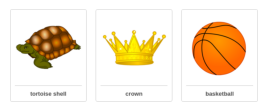

[1/64] Which property do these three objects have in common?
A. shiny
B. slippery
C. opaque
Return only the letter of the correct option.
  Ответ 1: 'C'
  Ответ 2: 'C'
  Ответ 3: 'C'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


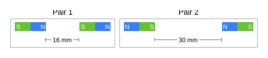

[2/64] Think about the magnetic force between the magnets in each pair. Which of the following statements is true?
A. The magnetic force is stronger in Pair 2.
B. The magnetic force is stronger in Pair 1.
C. The strength of the magnetic force is the same in both pairs.
Return only the letter of the correct option.
  Ответ 1: 'B'
  Ответ 2: 'B'
  Ответ 3: 'B'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


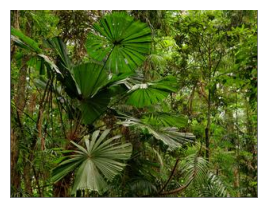

[3/64] Which better describes the Daintree rain forest ecosystem?
A. It has year-round rain. It also has soil that is poor in nutrients.
B. It has cold winters. It also has many different types of organisms.
Return only the letter of the correct option.
  Ответ 1: 'A'
  Ответ 2: 'A'
  Ответ 3: 'A'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


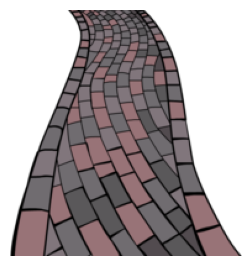

[4/64] Which material is this path made of?
A. plastic
B. brick
Return only the letter of the correct option.
  Ответ 1: 'B'
  Ответ 2: 'B'
  Ответ 3: 'B'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


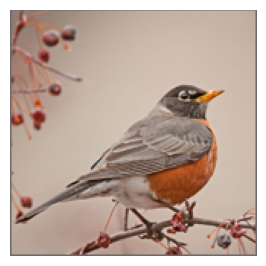

[5/64] Select the bird below.
A. cane toad
B. ostrich
Return only the letter of the correct option.
  Ответ 1: 'C'
  Ответ 2: 'B'
  Ответ 3: 'B'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 2,3
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 1
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


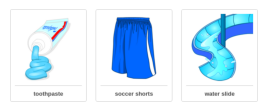

[6/64] Which property do these three objects have in common?
A. blue
B. hard
C. sticky
Return only the letter of the correct option.
  Ответ 1: 'A'
  Ответ 2: 'A'
  Ответ 3: 'A'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0


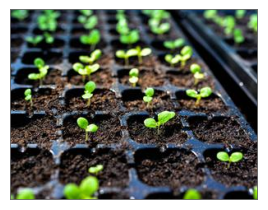

[7/64] Which of the following was a dependent variable in this experiment?
A. the temperature of the heating pad
B. the number of days until a seed germinated
Return only the letter of the correct option.
  Ответ 1: 'B'
  Ответ 2: 'B'
  Ответ 3: 'B'
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


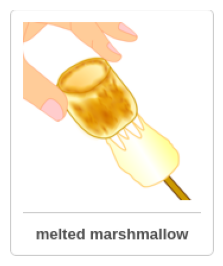

[8/64] Which property matches this object?
A. stretchy
B. blue
Return only the letter of the correct option.
  Ответ 1: 'A'
  Ответ 2: 'A'
  Ответ 3: 'A'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


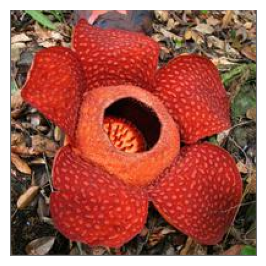

[9/64] Is Rafflesia arnoldii made up of many cells?
A. yes
B. no
Return only the letter of the correct option.
  Ответ 1: 'B'
  Ответ 2: 'B'
  Ответ 3: 'B.'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 1,2,3
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 3


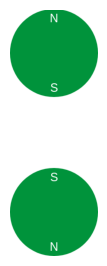

[10/64] Will these magnets attract or repel each other?
A. repel
B. attract
Return only the letter of the correct option.
  Ответ 1: 'A'
  Ответ 2: 'A'
  Ответ 3: 'A'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


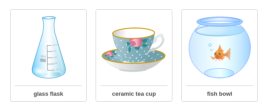

[11/64] Which property do these three objects have in common?
A. fragile
B. bouncy
C. yellow
Return only the letter of the correct option.
  Ответ 1: 'A'
  Ответ 2: 'A'
  Ответ 3: 'A'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


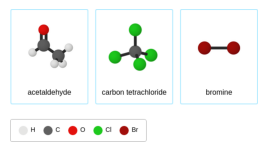

[12/64] Look at the models of molecules below. Select the elementary substance.
A. carbon tetrachloride
B. acetaldehyde
C. bromine
Return only the letter of the correct option.
  Ответ 1: 'C'
  Ответ 2: 'C'
  Ответ 3: 'C'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


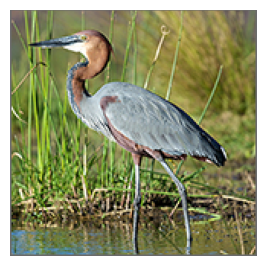

[13/64] Select the organism in the same genus as the Goliath heron.
A. Falco sparverius
B. Ardea herodias
C. Tigrisoma mexicanum
Return only the letter of the correct option.
  Ответ 1: 'B'
  Ответ 2: 'B'
  Ответ 3: 'B'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


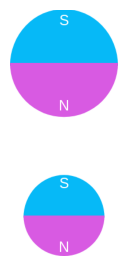

[14/64] Will these magnets attract or repel each other?
A. repel
B. attract
Return only the letter of the correct option.
  Ответ 1: 'A'
  Ответ 2: 'A'
  Ответ 3: 'B'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 3
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 1,2
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


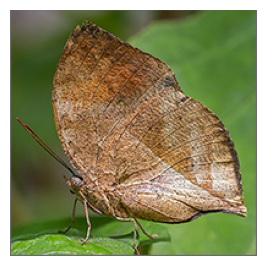

[15/64] Which animal is also adapted to be camouflaged among dead leaves?
A. strawberry poison frog
B. Surinam horned frog
Return only the letter of the correct option.
  Ответ 1: 'B'
  Ответ 2: 'B'
  Ответ 3: 'B'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


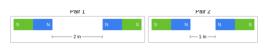

[16/64] Think about the magnetic force between the magnets in each pair. Which of the following statements is true?
A. The magnetic force is stronger in Pair 1.
B. The magnetic force is stronger in Pair 2.
C. The strength of the magnetic force is the same in both pairs.
Return only the letter of the correct option.
  Ответ 1: 'B'
  Ответ 2: 'B'
  Ответ 3: 'B'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


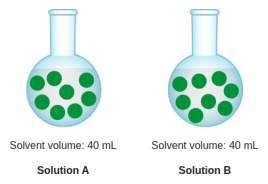

[17/64] Which solution has a higher concentration of green particles?
A. Solution B
B. neither; their concentrations are the same
C. Solution A
Return only the letter of the correct option.
  Ответ 1: 'C'
  Ответ 2: 'C'
  Ответ 3: 'B'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 3
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 1,2
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


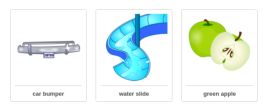

[18/64] Which property do these three objects have in common?
A. smooth
B. stretchy
C. fuzzy
Return only the letter of the correct option.
  Ответ 1: 'A'
  Ответ 2: 'A'
  Ответ 3: 'A'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


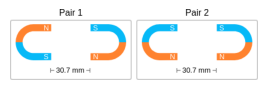

[19/64] Think about the magnetic force between the magnets in each pair. Which of the following statements is true?
A. The magnitude of the magnetic force is smaller in Pair 2.
B. The magnitude of the magnetic force is smaller in Pair 1.
C. The magnitude of the magnetic force is the same in both pairs.
Return only the letter of the correct option.
  Ответ 1: 'C'
  Ответ 2: 'C'
  Ответ 3: 'C'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


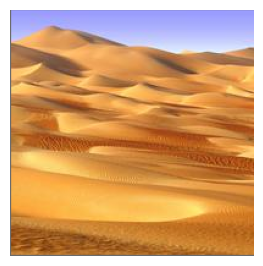

[20/64] Which rock is more likely to form from sediment deposited in a desert?
A. Sandstone forms from layers of sand.
B. Shale forms from layers of mud.
Return only the letter of the correct option.
  Ответ 1: 'A'
  Ответ 2: 'A'
  Ответ 3: 'A'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


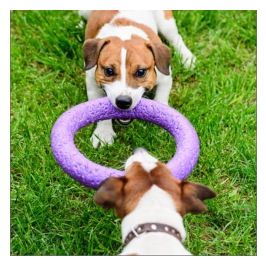

[21/64] As Rusty pulls on the toy, what is the direction of the opposing force?
A. away from Coco
B. toward Coco
Return only the letter of the correct option.
  Ответ 1: 'B'
  Ответ 2: 'B'
  Ответ 3: 'B'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


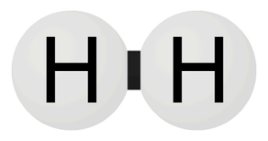

[22/64] Complete the statement.
Hydrogen is ().
A. an elementary substance
B. a compound
Return only the letter of the correct option.
  Ответ 1: 'A'
  Ответ 2: 'A'
  Ответ 3: 'A'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


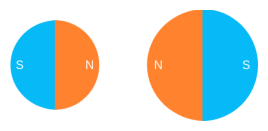

[23/64] Will these magnets attract or repel each other?
A. repel
B. attract
Return only the letter of the correct option.
  Ответ 1: 'A'
  Ответ 2: 'A'
  Ответ 3: 'A'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


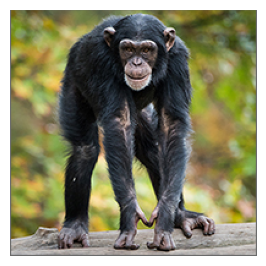

[24/64] Which animal's limbs are also adapted for climbing trees?
A. three-toed sloth
B. sea turtle
Return only the letter of the correct option.
  Ответ 1: 'A'
  Ответ 2: 'A'
  Ответ 3: 'A'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


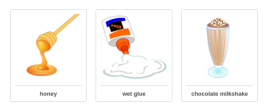

[25/64] Which property do these three objects have in common?
A. salty
B. scratchy
C. sticky
Return only the letter of the correct option.
  Ответ 1: 'C'
  Ответ 2: 'C'
  Ответ 3: 'C'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


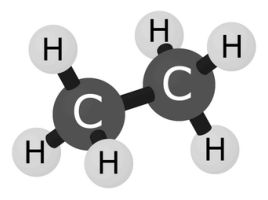

[26/64] Complete the statement.
Ethane is ().
A. an elementary substance
B. a compound
Return only the letter of the correct option.
  Ответ 1: 'B'
  Ответ 2: 'B'
  Ответ 3: 'B'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


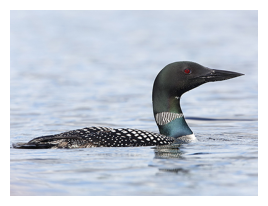

[27/64] Which is this organism's scientific name?
A. Gavia immer
B. common loon
Return only the letter of the correct option.
  Ответ 1: 'A'
  Ответ 2: 'B.'
  Ответ 3: 'A'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 1,3
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 2
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 2


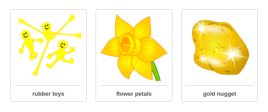

[28/64] Which property do these three objects have in common?
A. slippery
B. transparent
C. yellow
Return only the letter of the correct option.
  Ответ 1: 'C'
  Ответ 2: 'C'
  Ответ 3: 'C'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


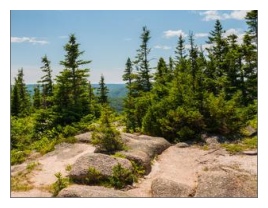

[29/64] Which statement describes the Cape Breton Highlands National Park ecosystem?
A. It has soil that is rich in nutrients.
B. It has many evergreen trees.
Return only the letter of the correct option.
  Ответ 1: 'B'
  Ответ 2: 'B'
  Ответ 3: 'B'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


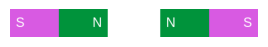

[30/64] Will these magnets attract or repel each other?
A. attract
B. repel
Return only the letter of the correct option.
  Ответ 1: 'B'
  Ответ 2: 'B.'
  Ответ 3: 'B'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 2


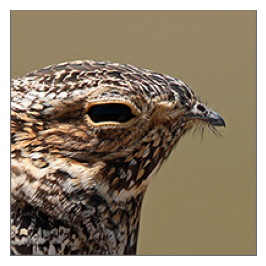

[31/64] Which bird's beak is also adapted to catch insects?
A. barn swallow
B. hanging parrot
Return only the letter of the correct option.
  Ответ 1: 'A'
  Ответ 2: 'A'
  Ответ 3: 'A'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


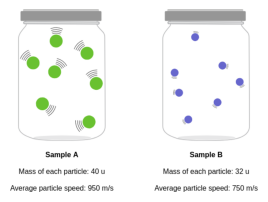

[32/64] Compare the average kinetic energies of the particles in each sample. Which sample has the higher temperature?
A. neither; the samples have the same temperature
B. sample A
C. sample B
Return only the letter of the correct option.
  Ответ 1: 'B'
  Ответ 2: 'B'
  Ответ 3: 'B'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


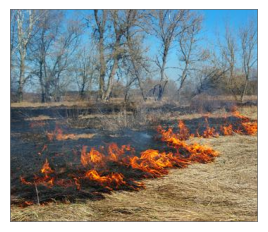

[33/64] What evidence of a wildfire does this picture show?
A. The grass is brown and dry.
B. Some of the grass on the ground is burning.
Return only the letter of the correct option.
  Ответ 1: 'B'
  Ответ 2: 'B'
  Ответ 3: 'B'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


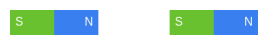

[34/64] Will these magnets attract or repel each other?
A. repel
B. attract
Return only the letter of the correct option.
  Ответ 1: 'B'
  Ответ 2: 'B'
  Ответ 3: 'A.'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 1,2
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 3
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 3


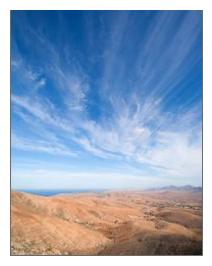

[35/64] Does this passage describe the weather or the climate?
A. weather
B. climate
Return only the letter of the correct option.
  Ответ 1: 'A'
  Ответ 2: 'B'
  Ответ 3: 'B'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 1
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 2,3
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


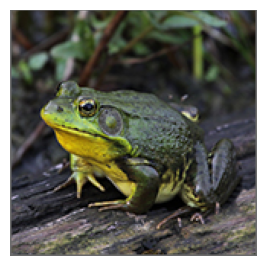

[36/64] Select the amphibian below.
A. brown tree frog
B. woodpecker
Return only the letter of the correct option.
  Ответ 1: 'A'
  Ответ 2: 'A'
  Ответ 3: 'A'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


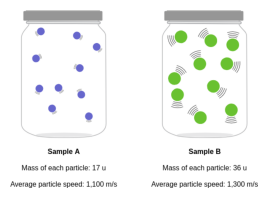

[37/64] Compare the average kinetic energies of the particles in each sample. Which sample has the higher temperature?
A. sample A
B. sample B
C. neither; the samples have the same temperature
Return only the letter of the correct option.
  Ответ 1: 'B'
  Ответ 2: 'B'
  Ответ 3: 'B'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


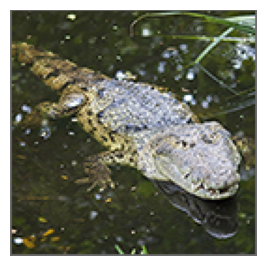

[38/64] What is the Morelet's crocodile's scientific name?
A. Crocodylus moreletii
B. Crocodylus anthropophagus
Return only the letter of the correct option.
  Ответ 1: 'A'
  Ответ 2: 'A'
  Ответ 3: 'A'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


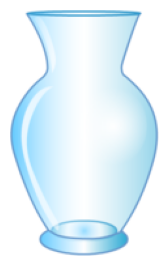

[39/64] Which material is this flower vase made of?
A. silk
B. glass
Return only the letter of the correct option.
  Ответ 1: 'B'
  Ответ 2: 'B'
  Ответ 3: 'B'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


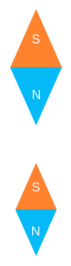

[40/64] Will these magnets attract or repel each other?
A. repel
B. attract
Return only the letter of the correct option.
  Ответ 1: 'B'
  Ответ 2: 'B'
  Ответ 3: 'A'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 1,2
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 3
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


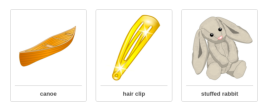

[41/64] Which property do these three objects have in common?
A. translucent
B. opaque
C. fragile
Return only the letter of the correct option.
  Ответ 1: 'B'
  Ответ 2: 'B'
  Ответ 3: 'B'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


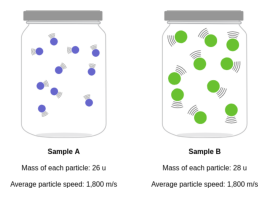

[42/64] Compare the average kinetic energies of the particles in each sample. Which sample has the higher temperature?
A. neither; the samples have the same temperature
B. sample A
C. sample B
Return only the letter of the correct option.
  Ответ 1: 'C'
  Ответ 2: 'C'
  Ответ 3: 'C'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


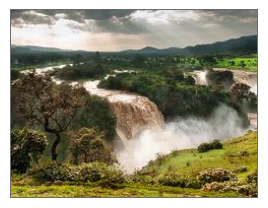

[43/64] Does this passage describe the weather or the climate?
A. climate
B. weather
Return only the letter of the correct option.
  Ответ 1: 'A'
  Ответ 2: 'B'
  Ответ 3: 'B'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 2,3
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 1
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 0


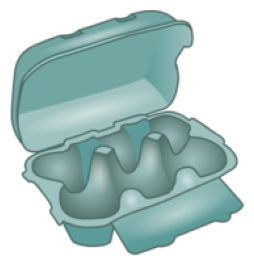

[44/64] Which material is this egg carton made of?
A. wood
B. styrofoam
Return only the letter of the correct option.
  Ответ 1: 'B'
  Ответ 2: 'B'
  Ответ 3: 'B'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


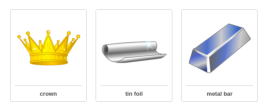

[45/64] Which property do these three objects have in common?
A. shiny
B. fuzzy
C. blue
Return only the letter of the correct option.
  Ответ 1: 'A'
  Ответ 2: 'A'
  Ответ 3: 'A'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


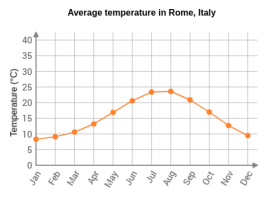

[46/64] Which month is the hottest on average in Rome?
A. December, January, and February
B. July and August
C. March and April
Return only the letter of the correct option.
  Ответ 1: 'B'
  Ответ 2: 'B'
  Ответ 3: 'B'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


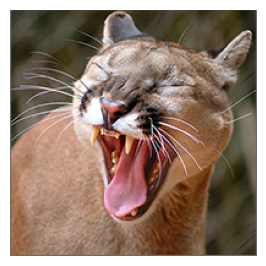

[47/64] Which animal's mouth is also adapted to tear through meat?
A. tiger
B. marmot
Return only the letter of the correct option.
  Ответ 1: 'A'
  Ответ 2: 'A'
  Ответ 3: 'A'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


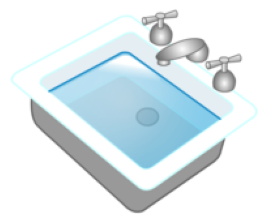

[48/64] Is the water in a sink a solid or a liquid?
A. a liquid
B. a solid
Return only the letter of the correct option.
  Ответ 1: 'A'
  Ответ 2: 'A'
  Ответ 3: 'A'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


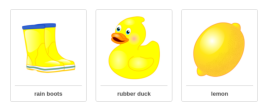

[49/64] Which property do these three objects have in common?
A. rough
B. yellow
C. sticky
Return only the letter of the correct option.
  Ответ 1: 'B'
  Ответ 2: 'B'
  Ответ 3: 'B'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


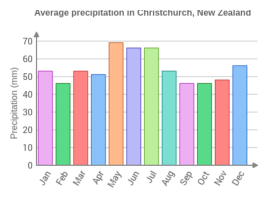

[50/64] Which month is the wettest on average in Christchurch?
A. August
B. April
C. May
Return only the letter of the correct option.
  Ответ 1: 'C'
  Ответ 2: 'C'
  Ответ 3: 'C'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


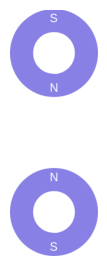

[51/64] Will these magnets attract or repel each other?
A. repel
B. attract
Return only the letter of the correct option.
  Ответ 1: 'A'
  Ответ 2: 'A'
  Ответ 3: 'A'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


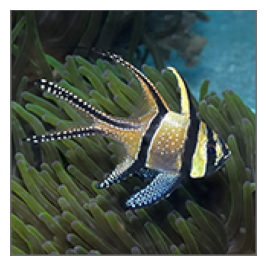

[52/64] Select the fish below.
A. water buffalo
B. poison dart frog
C. great white shark
D. penguin
Return only the letter of the correct option.
  Ответ 1: 'C'
  Ответ 2: 'C'
  Ответ 3: 'A'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 1,2
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 3
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


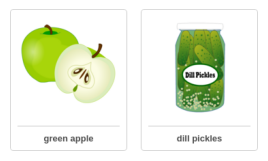

[53/64] Which property do these two objects have in common?
A. sour
B. stretchy
Return only the letter of the correct option.
  Ответ 1: 'A'
  Ответ 2: 'A'
  Ответ 3: 'A'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


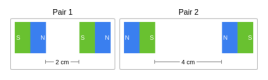

[54/64] Think about the magnetic force between the magnets in each pair. Which of the following statements is true?
A. The magnetic force is stronger in Pair 2.
B. The strength of the magnetic force is the same in both pairs.
C. The magnetic force is stronger in Pair 1.
Return only the letter of the correct option.
  Ответ 1: 'A'
  Ответ 2: 'A'
  Ответ 3: 'C'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 3
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 1,2
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


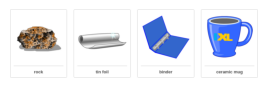

[55/64] Which property do these four objects have in common?
A. opaque
B. fragile
C. smooth
Return only the letter of the correct option.
  Ответ 1: 'A'
  Ответ 2: 'A'
  Ответ 3: 'A'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


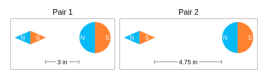

[56/64] Think about the magnetic force between the magnets in each pair. Which of the following statements is true?
A. The magnitude of the magnetic force is smaller in Pair 1.
B. The magnitude of the magnetic force is smaller in Pair 2.
C. The magnitude of the magnetic force is the same in both pairs.
Return only the letter of the correct option.
  Ответ 1: 'B'
  Ответ 2: 'B'
  Ответ 3: 'A'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 1,2
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 3
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


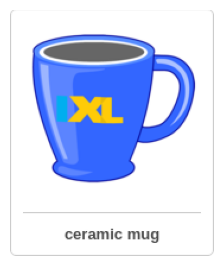

[57/64] Which property matches this object?
A. flexible
B. fragile
Return only the letter of the correct option.
  Ответ 1: 'B'
  Ответ 2: 'B'
  Ответ 3: 'B'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


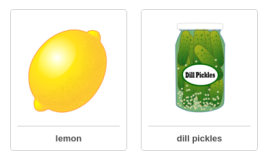

[58/64] Which property do these two objects have in common?
A. sour
B. blue
Return only the letter of the correct option.
  Ответ 1: 'A'
  Ответ 2: 'A'
  Ответ 3: 'A'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


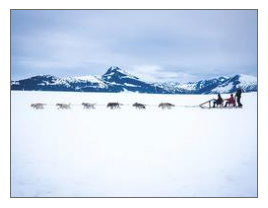

[59/64] What is the direction of this pull?
A. away from the sled dog team
B. toward the sled dog team
Return only the letter of the correct option.
  Ответ 1: 'B.'
  Ответ 2: 'B'
  Ответ 3: 'B'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 1


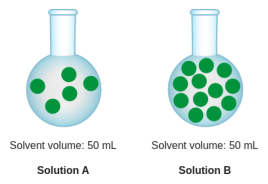

[60/64] Which solution has a higher concentration of green particles?
A. Solution A
B. neither; their concentrations are the same
C. Solution B
Return only the letter of the correct option.
  Ответ 1: 'C'
  Ответ 2: 'C'
  Ответ 3: 'C'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


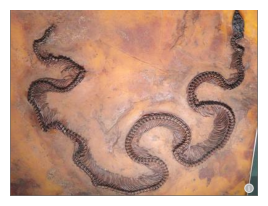

[61/64] Which trait did Palaeopython have? Select the trait you can observe on the fossil.
A. black stripes on its skin
B. large fins on its body
C. a long, thin body
Return only the letter of the correct option.
  Ответ 1: 'C'
  Ответ 2: 'C'
  Ответ 3: 'C'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


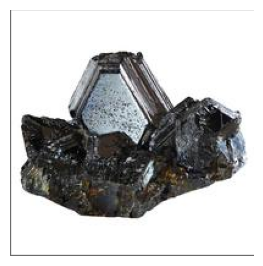

[62/64] Is sphalerite a mineral?
A. no
B. yes
Return only the letter of the correct option.
  Ответ 1: 'B'
  Ответ 2: 'B.'
  Ответ 3: 'B'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


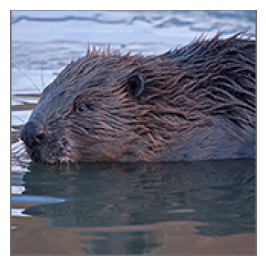

[63/64] Select the organism in the same species as the Eurasian beaver.
A. Castor fiber
B. Ovis canadensis
C. Lontra canadensis
Return only the letter of the correct option.
  Ответ 1: 'A'
  Ответ 2: 'A'
  Ответ 3: 'A'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 


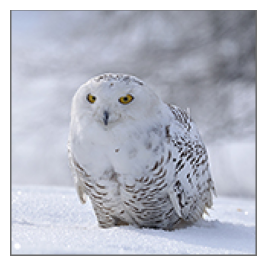

[64/64] Select the organism in the same species as the snowy owl.
A. Bubo scandiacus
B. Ardea herodias
C. Pelecanus erythrorhynchos
Return only the letter of the correct option.
  Ответ 1: 'A'
  Ответ 2: 'A'
  Ответ 3: 'A'
Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): 0
Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): 
Ответы с нарушением формата «одна буква» (номера, пусто = нет): 
оценено: 64 | pending: 0


In [12]:
# --- объективная метрика: EM по эталонным буквам (это НЕ человеческий win rate)
def em(rows, pol): return float(np.mean([extract_letter(b[pol]) == b['gold'] for b in rows]))
def fmt(rows, pol): return float(np.mean([bool(FORMAT_RE.fullmatch(b[pol].strip())) for b in rows]))
objective = {'metric': 'EM: ведущая буква ответа равна эталонной (ошибка формата = неверно); не человеческий win rate', 'n': len(blind),
             'exact_match': {p: em(blind, p) for p in POLICIES}, 'format_rate': {p: fmt(blind, p) for p in POLICIES}}
save_json('objective_scores.json', objective); print(json.dumps(objective, ensure_ascii=False))

# --- форма ручной слепой проверки (политики скрыты и перемешаны для каждого ID); пропуск = pending, а не 0
import matplotlib.pyplot as plt
J_PATH = ARTIFACTS / 'blind_judgements.jsonl'
def load_judgements():
    cur = {r['id']: r for r in load_jsonl(J_PATH)}
    return [cur.get(b['id'], {'id': b['id'], 'status': 'pending'}) for b in blind]
def save_judgements(rows): J_PATH.write_text(''.join(json.dumps(r, ensure_ascii=False) + '\n' for r in rows))
def parse_nums(s):
    return sorted({int(x) for x in re.findall(r'\d', s) if x in '123'})

def run_form(reviewer):
    rows = load_judgements(); bi = {b['id']: b for b in blind}; rec = {r['id']: r for r in test_recs}
    for k, j in enumerate(rows):
        if j['status'] == 'done': continue
        b, order = bi[j['id']], blind_key[j['id']]
        plt.figure(figsize=(3.2, 3.2)); plt.imshow(Image.open(rec[j['id']]['image'])); plt.axis('off'); plt.show()
        print(f"[{k + 1}/{len(rows)}] {rec[j['id']]['question']}")
        for n, pol in enumerate(order, 1): print(f'  Ответ {n}: {b[pol]!r}')
        s = input('Лучшие ответы (номера через запятую, 0 = равнозначны, s = пропустить, q = выход): ').strip().lower()
        if s == 'q': break
        if s == 's' or not s: continue
        best = [] if s == '0' else parse_nums(s)
        if s != '0' and not best: print('не распознано, оставлено pending'); continue
        hall = parse_nums(input('Ответы с галлюцинацией/неверным утверждением об изображении (номера, пусто = нет): '))
        badf = parse_nums(input('Ответы с нарушением формата «одна буква» (номера, пусто = нет): '))
        by_pol = lambda nums: {order[n - 1]: (n in nums) for n in (1, 2, 3)}
        rows[k] = {'id': j['id'], 'status': 'done', 'best': [order[n - 1] for n in best], 'tie_all': s == '0', 'hallucination': by_pol(hall),
                   'format_violation': by_pol(badf), 'reviewer': reviewer, 'timestamp': time.strftime('%Y-%m-%dT%H:%M:%S')}
        save_judgements(rows)
    save_judgements(rows); return rows

rows_j = load_judgements(); save_judgements(rows_j)
if any(r['status'] == 'pending' for r in rows_j) and not FAST_DEV_RUN:
    rows_j = run_form(input('Имя/идентификатор эксперта: ').strip() or 'reviewer')
print('оценено:', sum(r['status'] == 'done' for r in rows_j), '| pending:', sum(r['status'] == 'pending' for r in rows_j))

### Эффект DPO

*Вес: 1 балл.*

**Постановка.** Сопоставьте EM трёх политик, а по заполненным суждениям — win rate, hallucination rate и соблюдение формата. Укажите число оценённых записей и ограничения label-derived предпочтений.

**Результат.** blind_report.json и вывод.

**Критерий принятия.** Метрики имеют реальные знаменатели; pending-оценка не выдаётся за завершённую; вывод не обобщает предпочтение правильной буквы на безопасность или универсальную полезность.


In [13]:
done = [r for r in load_judgements() if r['status'] == 'done']; n_total = len(blind); n_done = len(done); n_pending = n_total - n_done
def verdict(a, b, rows):
    w = sum((a in r['best']) and (b not in r['best']) for r in rows); l = sum((b in r['best']) and (a not in r['best']) for r in rows)
    t = len(rows) - w - l
    return {'wins': w, 'losses': l, 'ties': t, 'n': len(rows), 'win_rate_excl_ties': w / (w + l) if (w + l) else None, 'win_rate_ties_half': (w + .5 * t) / len(rows) if rows else None}
manual = {'n_judged': n_done, 'n_pending': n_pending, 'n_total': n_total, 'status': 'complete' if n_pending == 0 and n_done > 0 else 'incomplete'}
if n_done:
    manual.update({'aligned_vs_reference': verdict('aligned', 'reference', done), 'aligned_vs_foundation': verdict('aligned', 'foundation', done),
                   'hallucination_rate': {p: float(np.mean([r['hallucination'][p] for r in done])) for p in POLICIES},
                   'format_compliance': {p: float(np.mean([not r['format_violation'][p] for r in done])) for p in POLICIES}})
else:
    manual['note'] = 'ручная проверка не заполнена: ручные метрики не вычисляются (pending не равен нулю)'
report = {'objective': objective, 'manual': manual, 'dpo': {'steps': STEPS, 'pairs': N_PAIRS, 'beta': BETA, 'lr': LR_DPO, 'reference_mode': REF_MODE},
          'limitations': ['предпочтения построены из эталонных букв ScienceQA (chosen=верный, rejected=следующий вариант), а не из оценок людей',
                          'вывод не переносится на безопасность, полезность или стиль ответов', 'n = %d изображений ID test: интервалы широки' % n_total,
                          'при lr=5e-6 и 40 шагах сдвиг политики может быть малым'] + ([] if REF_MODE == 'adapter09' else ['собственного SFT (работа 09) не было: reference = исходная модель'])}
concl = [f"EM (n={n_total}): " + ', '.join(f"{p}={objective['exact_match'][p]:.3f}" for p in POLICIES)]
if n_done:
    a = manual['aligned_vs_reference']; concl.append(f"ручная оценка ({n_done}/{n_total}, pending {n_pending}): aligned vs reference: {a['wins']} побед / {a['losses']} поражений / {a['ties']} ничьих")
    concl.append('галлюцинации: ' + ', '.join(f"{p}={manual['hallucination_rate'][p]:.2f}" for p in POLICIES))
else: concl.append('ручная проверка не заполнена - итоговый win rate не создаётся')
report['conclusion'] = concl; save_json('blind_report.json', report); print('\n'.join(concl))

EM (n=64): foundation=0.875, reference=0.906, aligned=0.922
ручная оценка (64/64, pending 0): aligned vs reference: 1 побед / 0 поражений / 63 ничьих
галлюцинации: foundation=0.14, reference=0.08, aligned=0.06


### Творческое мини-исследование

*Бонус: до 1 балла сверх 10.*

**Постановка.** Сформулируйте проверяемую гипотезу о предметном ограничении метода данной лабораторной и проверьте её на дополнительных реальных входах без использования отложенного теста для выбора гипотезы. Сопоставьте результаты с основным экспериментом и объясните расхождения.

**Результат.** Отдельный файл artifacts/bonus.md с гипотезой, протоколом, наблюдениями и выводом.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена по сохранённым предсказаниям или изображениям и приведено воспроизводимое сравнение.

## Анализ результатов

Сопоставьте измеренные показатели на фиксированной отложенной выборке, укажите ограничения выборки и разберите ошибки по сохранённым предсказаниям. FAST_DEV_RUN не является основанием для итогового вывода.

## Требования к сдаче

Запустите полный режим, приложите конфигурацию, версии зависимостей, артефакты и инструкции повторного запуска. Не сдавайте фиктивные измерения.

## Инструкция повторного запуска

1. Colab, GPU T4: `%pip install -q "transformers>=4.51,<5" accelerate bitsandbytes peft datasets pillow matplotlib scikit-learn`. Версии зависимостей записываются в `artifacts/environment.json`.
2. Адаптер работы 09: `CV_LAB9_ADAPTER=/путь/к/artifacts/lab9_adapter` (или лежит в `artifacts/lab9_adapter`) — тогда политика и reference стартуют с него. Без адаптера обе политики стартуют с исходной Qwen2.5-VL-3B-Instruct, и это записывается в `reference_policy.json`.
3. `FAST_DEV_RUN=True` — 2 optimizer step × 2 пары на smoke-манифесте (проверка механики). `False` — 40 optimizer steps × 8 пар, ответы на 64 ID test, затем ручная слепая проверка (интерактивная ячейка, её заполняет человек).
4. DPO реализован собственным циклом: reference log-prob считается заранее без градиентов, обучается только LoRA `default`, NaN вызывает ошибку.

In [14]:
import importlib.metadata as md
def ver(n):
    try: return md.version(n)
    except Exception: return None
save_json('environment.json', {'versions': {n: ver(n) for n in ['torch', 'transformers', 'peft', 'bitsandbytes', 'accelerate', 'datasets', 'trl']},
                               'gpu': torch.cuda.get_device_name(0), 'config': {'SEED': SEED, 'FAST_DEV_RUN': FAST_DEV_RUN, 'MODEL_ID': MODEL_ID, 'REF_MODE': REF_MODE,
                               'BETA': BETA, 'LR_DPO': LR_DPO, 'STEPS': STEPS, 'ACCUM': ACCUM, 'SCIENCEQA_REVISION': SCIENCEQA_REVISION}})
print(sorted(p.name for p in ARTIFACTS.iterdir()))

['aligned_adapter', 'answers_aligned.jsonl', 'answers_foundation.jsonl', 'answers_reference.jsonl', 'blind_judgements.jsonl', 'blind_key.json', 'blind_predictions.jsonl', 'blind_report.json', 'dpo_metrics.json', 'dpo_protocol.json', 'environment.json', 'lab9_adapter', 'lab9_adapter.zip', 'objective_scores.json', 'pair_audit.json', 'preferences.jsonl', 'reference_policy.json']
